# Rain classifier v1 — will it rain tomorrow?

Predicts the **probability of a wet day (≥ 1 mm)** at t+1, t+2, t+3 from the same station data as Champion v2.

- Features come from `src/features.py` (shared with the live `predict.py`).
- Baselines: **climatology** (how often it rains on this date) and a **Markov baseline** (chance of rain tomorrow given rain/no rain today, by month).
- Scored with the **Brier score** (mean squared error of probabilities) and **Brier skill vs climatology**, plus ROC AUC and a reliability check.
- Same test period as the temperature model (from 2019-08-26).

In [1]:
import sys
from pathlib import Path
ROOT = Path('..') if Path('../src').exists() else Path('.')
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, joblib, warnings
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import brier_score_loss, roc_auc_score, precision_score, recall_score
from sklearn.calibration import calibration_curve
from src.features import load_station_csv, fit_climatology, build_features, temp_feature_list, RAIN_EXTRA, WET_DAY_MM
warnings.filterwarnings('ignore')
(ROOT/'models').mkdir(exist_ok=True); (ROOT/'images').mkdir(exist_ok=True)
TEST_START = pd.Timestamp('2019-08-26'); HORIZONS = [1, 2, 3]; SEED = 42

## 1. Data and features

In [2]:
daily = load_station_csv(ROOT/'data'/'df_analysis.csv')
clim = fit_climatology(daily[daily.index < TEST_START])
df = build_features(daily, clim)
FEATURES = temp_feature_list(df) + RAIN_EXTRA
df['wet'] = (df['Precipitation_mm'] >= WET_DAY_MM).astype(int)
for h in HORIZONS:
    df[f'y_t{h}'] = df['wet'].shift(-h)
    df[f'clim_t{h}'] = clim['rain_prob'].reindex(((df['Day_of_Year'] + h - 1) % 366) + 1).values
data = df.dropna(subset=FEATURES + [f'y_t{h}' for h in HORIZONS])
train, test = data[data.index < TEST_START], data[data.index >= TEST_START]
print(f'{len(FEATURES)} features | train {len(train)} | test {len(test)} | wet-day rate (test): {test.wet.mean():.1%}')

37 features | train 7513 | test 1877 | wet-day rate (test): 31.0%


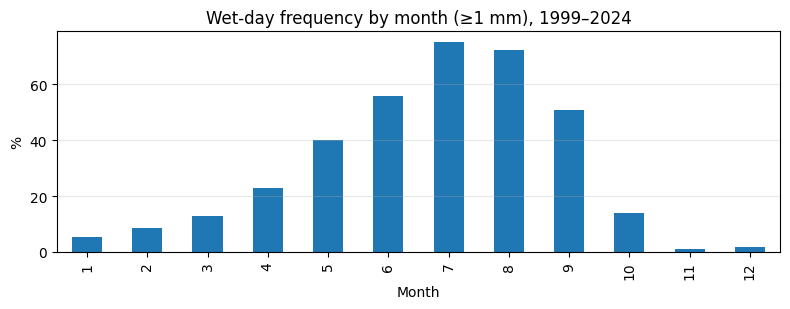

In [3]:
ax = (daily.assign(wet=daily.Precipitation_mm >= WET_DAY_MM).groupby(daily.index.month).wet.mean()*100).plot.bar(
    figsize=(8, 3.2), title='Wet-day frequency by month (≥1 mm), 1999–2024', xlabel='Month', ylabel='%')
ax.grid(axis='y', alpha=.3); plt.tight_layout(); plt.savefig(ROOT/'images'/'rain_monthly_frequency.png', dpi=120); plt.show()

## 2. Baselines

In [4]:
probs = {}
tr_month = train.index.month
for h in HORIZONS:
    y_tr = train[f'y_t{h}']
    probs[('Climatology', h)] = test[f'clim_t{h}']
    # Markov baseline: P(wet at t+h | wet today, month) from training data
    table = y_tr.groupby([tr_month, train['wet']]).mean()
    probs[('Markov (wet today × month)', h)] = pd.Series(
        [table.get((m, w), np.nan) for m, w in zip(test.index.month, test['wet'])], index=test.index)

## 3. XGBoost classifier, one per horizon

In [5]:
param_dist = {'n_estimators': [200, 400, 700], 'learning_rate': [0.01, 0.03, 0.05],
              'max_depth': [2, 3, 4], 'min_child_weight': [1, 5, 10, 20],
              'subsample': [0.7, 0.8, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0], 'reg_lambda': [1, 5, 10]}
models = {}
for h in HORIZONS:
    search = RandomizedSearchCV(
        xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=SEED, n_jobs=-1),
        param_dist, n_iter=15, cv=TimeSeriesSplit(5), scoring='neg_brier_score', random_state=SEED)
    search.fit(train[FEATURES], train[f'y_t{h}'])
    models[h] = search.best_estimator_
    probs[('XGBoost', h)] = pd.Series(models[h].predict_proba(test[FEATURES])[:, 1], index=test.index)
    print(f't+{h}: CV Brier {-search.best_score_:.4f} | {search.best_params_}')

t+1: CV Brier 0.1277 | {'subsample': 0.8, 'reg_lambda': 10, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


t+2: CV Brier 0.1412 | {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.8}


t+3: CV Brier 0.1434 | {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.8}


## 4. Results

In [6]:
rows = []
for (name, h), p in probs.items():
    y = test[f'y_t{h}']; ok = p.notna()
    rows.append({'Model': name, 'h': h, 'Brier': brier_score_loss(y[ok], p[ok]), 'AUC': roc_auc_score(y[ok], p[ok])})
res = pd.DataFrame(rows)
clim_b = res[res.Model == 'Climatology'].set_index('h')['Brier']
res['Brier skill vs clim'] = 1 - res['Brier'] / res['h'].map(clim_b)
order = ['Climatology', 'Markov (wet today × month)', 'XGBoost']
for metric, fmt in [('Brier', '{:.4f}'), ('Brier skill vs clim', '{:.1%}'), ('AUC', '{:.3f}')]:
    print(metric + (' (lower is better)' if metric == 'Brier' else ''))
    display(res.pivot(index='Model', columns='h', values=metric).loc[order].map(fmt.format))

Brier (lower is better)


h,1,2,3
Model,,,
Climatology,0.1355,0.1355,0.1352
Markov (wet today × month),0.1320,0.1379,0.1379
XGBoost,0.1152,0.1311,0.1328


Brier skill vs clim


h,1,2,3
Model,,,
Climatology,0.0%,0.0%,0.0%
Markov (wet today × month),2.6%,-1.8%,-2.0%
XGBoost,14.9%,3.2%,1.8%


AUC


h,1,2,3
Model,,,
Climatology,0.866,0.866,0.866
Markov (wet today × month),0.871,0.859,0.861
XGBoost,0.906,0.876,0.872


## 5. Reliability — when it says 70%, does it rain ~70% of the time?
For an app that shows a percentage, calibration matters more than AUC.

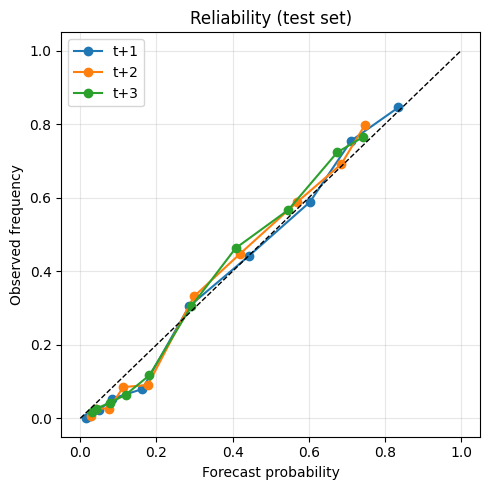

In [7]:
fig, ax = plt.subplots(figsize=(5, 5))
for h in HORIZONS:
    pt, pp = calibration_curve(test[f'y_t{h}'], probs[('XGBoost', h)], n_bins=10, strategy='quantile')
    ax.plot(pp, pt, 'o-', label=f't+{h}')
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set(xlabel='Forecast probability', ylabel='Observed frequency', title='Reliability (test set)')
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig(ROOT/'images'/'rain_reliability.png', dpi=120); plt.show()

## 6. Skill by season (t+1)

In [8]:
season = pd.Series(np.select([test.index.month.isin([12,1,2]), test.index.month.isin([3,4,5]), test.index.month.isin([6,7,8,9])],
                    ['Winter', 'Pre-monsoon', 'Monsoon'], 'Post-monsoon'), index=test.index)
rows = []
for s in ['Winter', 'Pre-monsoon', 'Monsoon', 'Post-monsoon']:
    i = season == s; y = test.loc[i, 'y_t1']
    bc = brier_score_loss(y, probs[('Climatology', 1)][i]); bx = brier_score_loss(y, probs[('XGBoost', 1)][i])
    rows.append({'Season': s, 'Days': int(i.sum()), 'Wet rate': f'{y.mean():.0%}',
                 'Brier clim': round(bc, 4), 'Brier XGB': round(bx, 4), 'Skill': f'{1 - bx/bc:.1%}'})
display(pd.DataFrame(rows))

,Season,Days,Wet rate,Brier clim,Brier XGB,Skill
0,Winter,452,4%,0.0426,0.0321,24.6%
1,Pre-monsoon,460,27%,0.1771,0.1473,16.8%
2,Monsoon,646,65%,0.2130,0.1881,11.7%
3,Post-monsoon,319,6%,0.0502,0.0393,21.6%


## 7. Umbrella flag for the app
The app needs a yes/no. Choose the probability threshold on **training** data, then check it on test.

In [9]:
p_tr = models[1].predict_proba(train[FEATURES])[:, 1]
cands = np.arange(0.2, 0.71, 0.05)
f1 = [2*precision_score(train.y_t1, p_tr >= t)*recall_score(train.y_t1, p_tr >= t) /
      max(precision_score(train.y_t1, p_tr >= t) + recall_score(train.y_t1, p_tr >= t), 1e-9) for t in cands]
UMBRELLA_THRESHOLD = float(round(cands[int(np.argmax(f1))], 2))
p_te = probs[('XGBoost', 1)]
flag = p_te >= UMBRELLA_THRESHOLD
print(f'Umbrella threshold (chosen on train): {UMBRELLA_THRESHOLD}')
print(f'Test: precision {precision_score(test.y_t1, flag):.2f} | recall {recall_score(test.y_t1, flag):.2f} | flagged {flag.mean():.0%} of days')

Umbrella threshold (chosen on train): 0.35
Test: precision 0.65 | recall 0.85 | flagged 40% of days


## 8. Feature importance (t+1)

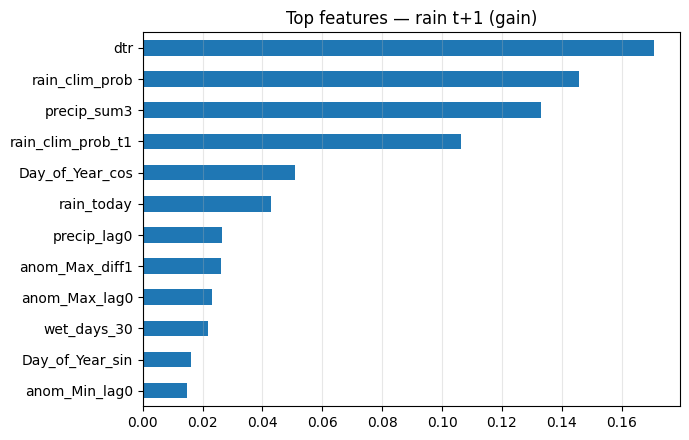

In [10]:
pd.Series(models[1].feature_importances_, index=FEATURES).sort_values().tail(12).plot.barh(
    figsize=(7, 4.5), title='Top features — rain t+1 (gain)'); plt.grid(axis='x', alpha=.3)
plt.tight_layout(); plt.savefig(ROOT/'images'/'rain_feature_importance.png', dpi=120); plt.show()

## 9. Save

In [11]:
from src.model_io import save_rain_models
save_rain_models(models, FEATURES, clim, UMBRELLA_THRESHOLD, WET_DAY_MM, {'test_start': str(TEST_START.date())})

Saved 3 models to ../models/rain_v1
